In [1]:
import sys
import numpy as np
import pandas as pd

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Python executable: C:\Users\moham\anaconda3\envs\timeseries\python.exe
Python version: 3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]
NumPy version: 2.4.6
Pandas version: 3.1.1


In [3]:

from pathlib import Path
import pandas as pd
import numpy as np

# Dataset directories
DATASET_PATH = Path(
    r"C:\Time_Series_Research\Project_02_VR_Emotion_Recognition\GSR_dataset"
)

nature_path = DATASET_PATH / "Nature"
subway_path = DATASET_PATH / "Subway"

# Verify directories
print("Nature folder exists:", nature_path.exists())
print("Subway folder exists:", subway_path.exists())

# Verify CSV counts
print("Nature files:", len(list(nature_path.glob("*.csv"))))
print("Subway files:", len(list(subway_path.glob("*.csv"))))


Nature folder exists: True
Subway folder exists: True
Nature files: 28
Subway files: 18


In [4]:
import pandas as pd

# Load S1 from both environments
nature_sample = pd.read_csv(nature_path / "S1_GSR_Nature.csv")
subway_sample = pd.read_csv(subway_path / "S1_GSR.csv")

print("NATURE — S1")
print("=" * 50)
print("Shape:", nature_sample.shape)
print("\nFirst 5 rows:")
display(nature_sample.head())

print("\nSUBWAY — S1")
print("=" * 50)
print("Shape:", subway_sample.shape)
print("\nFirst 5 rows:")
display(subway_sample.head())

print("\nCOLUMN TYPES — NATURE")
print(nature_sample.dtypes)

print("\nCOLUMN TYPES — SUBWAY")
print(subway_sample.dtypes)

NATURE — S1
Shape: (1888, 6)

First 5 rows:


,Time:4Hz,Epoch,Channel 1,Event Id,Event Date,Event Duration
0,0.00,0,1.169769,NaN,NaN,NaN
1,0.25,0,1.172330,NaN,NaN,NaN
2,0.50,0,1.169769,NaN,NaN,NaN
3,0.75,0,1.169769,NaN,NaN,NaN
4,1.00,0,1.168488,NaN,NaN,NaN



SUBWAY — S1
Shape: (1310, 6)

First 5 rows:


,Time:4Hz,Epoch,Channel 1,Event Id,Event Date,Event Duration
0,0.00,0,0.954583,NaN,NaN,NaN
1,0.25,0,0.972515,NaN,NaN,NaN
2,0.50,0,0.985324,NaN,NaN,NaN
3,0.75,0,0.986605,NaN,NaN,NaN
4,1.00,0,0.981481,NaN,NaN,NaN



COLUMN TYPES — NATURE
Time:4Hz          float64
Epoch               int64
Channel 1         float64
Event Id              str
Event Date            str
Event Duration        str
dtype: object

COLUMN TYPES — SUBWAY
Time:4Hz          float64
Epoch               int64
Channel 1         float64
Event Id              str
Event Date            str
Event Duration        str
dtype: object


In [5]:

import pandas as pd
import numpy as np

quality_results = []

for environment, folder, suffix in [
    ("Nature", nature_path, "_GSR_Nature"),
    ("Subway", subway_path, "_GSR")
]:
    for file in sorted(folder.glob("*.csv")):
        df = pd.read_csv(file)

        time_col = "Time:4Hz"
        signal_col = "Channel 1"

        time_values = pd.to_numeric(df[time_col], errors="coerce")
        signal_values = pd.to_numeric(df[signal_col], errors="coerce")

        time_diffs = time_values.diff().dropna()

        quality_results.append({
            "Environment": environment,
            "Participant": file.name.split("_")[0],
            "Samples": len(df),
            "Missing_Time": time_values.isna().sum(),
            "Missing_GSR": signal_values.isna().sum(),
            "Duplicate_Timestamps": time_values.duplicated().sum(),
            "Time_Start": time_values.min(),
            "Time_End": time_values.max(),
            "Median_Interval": time_diffs.median(),
            "Min_GSR": signal_values.min(),
            "Max_GSR": signal_values.max()
        })

quality_df = pd.DataFrame(quality_results)

print("DATA QUALITY SUMMARY")
print("=" * 60)

print("\nFiles inspected:", len(quality_df))

print("\nSummary by environment:")
display(
    quality_df.groupby("Environment")[
        ["Samples", "Missing_Time", "Missing_GSR",
         "Duplicate_Timestamps", "Median_Interval"]
    ].agg(["count", "sum", "mean"])
)

print("\nFiles with missing GSR values:")
display(quality_df[quality_df["Missing_GSR"] > 0])

print("\nFiles with missing timestamps:")
display(quality_df[quality_df["Missing_Time"] > 0])

print("\nFiles with unusual median sampling intervals:")
display(
    quality_df[
        ~np.isclose(
            quality_df["Median_Interval"],
            0.25,
            atol=0.001
        )
    ][["Environment", "Participant", "Median_Interval"]]
)


DATA QUALITY SUMMARY

Files inspected: 46

Summary by environment:


Samples                     Missing_Time          Missing_GSR      \
              count    sum         mean        count sum mean       count sum   
Environment                                                                     
Nature           28  36800  1314.285714           28   0  0.0          28   0   
Subway           18  20798  1155.444444           18   0  0.0          18   0   

                 Duplicate_Timestamps          Median_Interval             
            mean                count sum mean           count  sum  mean  
Environment                                                                
Nature       0.0                   28   0  0.0              28  7.0  0.25  
Subway       0.0                   18   0  0.0              18  4.5  0.25


Files with missing GSR values:


,Environment,Participant,Samples,Missing_Time,Missing_GSR,Duplicate_Timestamps,Time_Start,Time_End,Median_Interval,Min_GSR,Max_GSR



Files with missing timestamps:


,Environment,Participant,Samples,Missing_Time,Missing_GSR,Duplicate_Timestamps,Time_Start,Time_End,Median_Interval,Min_GSR,Max_GSR



Files with unusual median sampling intervals:


,Environment,Participant,Median_Interval


In [6]:

# Calculate recording duration for every participant

quality_df["Duration_Seconds"] = (
    quality_df["Time_End"] - quality_df["Time_Start"]
)

print("RECORDING DURATION ANALYSIS")
print("=" * 55)

for environment in ["Nature", "Subway"]:
    subset = quality_df[
        quality_df["Environment"] == environment
    ]

    print(f"\n{environment}")
    print("-" * 35)
    print("Number of recordings:", len(subset))
    print("Shortest recording:",
          round(subset["Duration_Seconds"].min(), 2), "seconds")
    print("Longest recording:",
          round(subset["Duration_Seconds"].max(), 2), "seconds")
    print("Average recording:",
          round(subset["Duration_Seconds"].mean(), 2), "seconds")
    print("Median recording:",
          round(subset["Duration_Seconds"].median(), 2), "seconds")

print("\nALL PARTICIPANT RECORDINGS")
display(
    quality_df[
        ["Environment", "Participant", "Samples",
         "Duration_Seconds", "Min_GSR", "Max_GSR"]
    ].sort_values(["Environment", "Participant"])
)


RECORDING DURATION ANALYSIS

Nature
-----------------------------------
Number of recordings: 28
Shortest recording: 7.75 seconds
Longest recording: 551.75 seconds
Average recording: 328.32 seconds
Median recording: 319.75 seconds

Subway
-----------------------------------
Number of recordings: 18
Shortest recording: 143.75 seconds
Longest recording: 327.25 seconds
Average recording: 288.61 seconds
Median recording: 295.75 seconds

ALL PARTICIPANT RECORDINGS


,Environment,Participant,Samples,Duration_Seconds,Min_GSR,Max_GSR
10,Nature,S1,1888,471.75,0.791912,6.482802
0,Nature,S10,1248,311.75,1.705265,3.459459
1,Nature,S11,1248,311.75,2.870144,3.645162
2,Nature,S12,1312,327.75,0.280510,0.327902
3,Nature,S13,1248,311.75,1.958908,4.895508
4,Nature,S14,1248,311.75,4.860456,6.110581
5,Nature,S15,1216,303.75,0.281791,0.508505
6,Nature,S16,1248,311.75,0.147300,0.306127
7,Nature,S17,1280,319.75,0.051232,0.083251
8,Nature,S18,1280,319.75,0.248740,0.561253


In [7]:

# Inspect the unusually short Nature S3 recording

nature_s3 = pd.read_csv(nature_path / "S3_GSR_Nature.csv")

print("NATURE S3 RECORDING")
print("=" * 50)

print("Shape:", nature_s3.shape)
print("\nFirst 10 rows:")
display(nature_s3.head(10))

print("\nLast 10 rows:")
display(nature_s3.tail(10))

print("\nNon-missing values in each column:")
print(nature_s3.notna().sum())

print("\nTime range:")
print(
    nature_s3["Time:4Hz"].min(),
    "to",
    nature_s3["Time:4Hz"].max()
)


NATURE S3 RECORDING
Shape: (32, 6)

First 10 rows:


,Time:4Hz,Epoch,Channel 1,Event Id,Event Date,Event Duration
0,0.00,0,7.137062,NaN,NaN,NaN
1,0.25,0,7.137062,NaN,NaN,NaN
2,0.50,0,7.137062,NaN,NaN,NaN
3,0.75,0,7.137062,NaN,NaN,NaN
4,1.00,0,7.137062,NaN,NaN,NaN
5,1.25,0,7.137062,NaN,NaN,NaN
6,1.50,0,7.137062,NaN,NaN,NaN
7,1.75,0,7.137062,NaN,NaN,NaN
8,2.00,0,7.137062,NaN,NaN,NaN
9,2.25,0,7.137062,NaN,NaN,NaN



Last 10 rows:


,Time:4Hz,Epoch,Channel 1,Event Id,Event Date,Event Duration
22,5.50,0,7.137062,NaN,NaN,NaN
23,5.75,0,7.137062,NaN,NaN,NaN
24,6.00,0,7.137062,NaN,NaN,NaN
25,6.25,0,7.137062,NaN,NaN,NaN
26,6.50,0,7.137062,NaN,NaN,NaN
27,6.75,0,7.137062,NaN,NaN,NaN
28,7.00,0,7.137062,NaN,NaN,NaN
29,7.25,0,7.137062,NaN,NaN,NaN
30,7.50,0,7.137062,NaN,NaN,NaN
31,7.75,0,7.137062,NaN,NaN,NaN



Non-missing values in each column:
Time:4Hz          32
Epoch             32
Channel 1         32
Event Id           0
Event Date         0
Event Duration     0
dtype: int64

Time range:
0.0 to 7.75


In [8]:

# Check GSR signal variability across all 46 recordings

variability_results = []

for environment, folder in [
    ("Nature", nature_path),
    ("Subway", subway_path)
]:
    for file in sorted(folder.glob("*.csv")):
        df = pd.read_csv(file)
        gsr = pd.to_numeric(df["Channel 1"], errors="coerce")

        variability_results.append({
            "Environment": environment,
            "Participant": file.name.split("_")[0],
            "Samples": len(gsr),
            "Unique_GSR_Values": gsr.nunique(),
            "GSR_Std": gsr.std(),
            "GSR_Mean": gsr.mean(),
            "GSR_Median": gsr.median()
        })

variability_df = pd.DataFrame(variability_results)

print("GSR SIGNAL VARIABILITY")
print("=" * 60)

print("\nConstant recordings (one unique value):")
display(
    variability_df[
        variability_df["Unique_GSR_Values"] <= 1
    ]
)

print("\nLowest 10 recordings by standard deviation:")
display(
    variability_df.sort_values("GSR_Std").head(10)
)


GSR SIGNAL VARIABILITY

Constant recordings (one unique value):


,Environment,Participant,Samples,Unique_GSR_Values,GSR_Std,GSR_Mean,GSR_Median
21,Nature,S3,32,1,0.0,7.137062,7.137062



Lowest 10 recordings by standard deviation:


,Environment,Participant,Samples,Unique_GSR_Values,GSR_Std,GSR_Mean,GSR_Median
21,Nature,S3,32,1,0.000000,7.137062,7.137062
7,Nature,S17,1280,21,0.004318,0.063815,0.064040
2,Nature,S12,1312,32,0.009080,0.302715,0.306127
33,Subway,S15,1216,41,0.009293,0.159039,0.161380
9,Nature,S19,1344,40,0.011053,0.163243,0.161380
25,Nature,S7,1472,31,0.011224,0.439283,0.436697
20,Nature,S2,2208,57,0.013663,0.087115,0.089661
15,Nature,S24,1280,45,0.015828,0.283327,0.281774
40,Subway,S4,1184,72,0.022563,0.194927,0.192397
45,Subway,S9,1088,63,0.025903,0.091545,0.106306


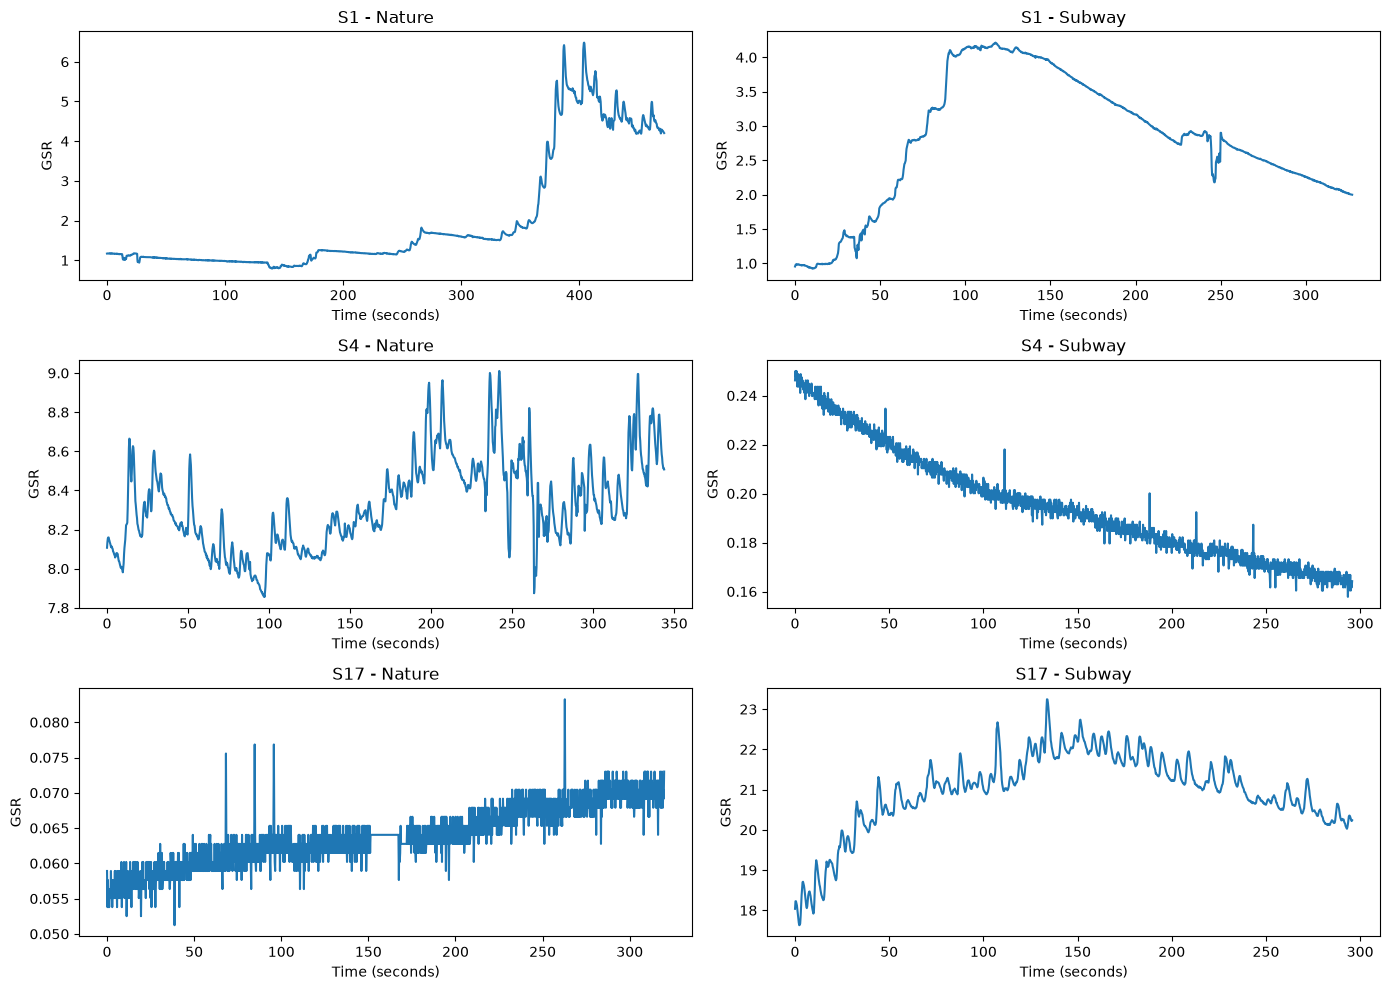

In [9]:

import matplotlib.pyplot as plt

participants_to_plot = ["S1", "S4", "S17"]

fig, axes = plt.subplots(
    len(participants_to_plot),
    2,
    figsize=(14, 10)
)

for row, participant in enumerate(participants_to_plot):

    nature_file = nature_path / f"{participant}_GSR_Nature.csv"
    subway_file = subway_path / f"{participant}_GSR.csv"

    nature_df = pd.read_csv(nature_file)
    subway_df = pd.read_csv(subway_file)

    axes[row, 0].plot(
        nature_df["Time:4Hz"],
        nature_df["Channel 1"]
    )
    axes[row, 0].set_title(f"{participant} - Nature")
    axes[row, 0].set_xlabel("Time (seconds)")
    axes[row, 0].set_ylabel("GSR")

    axes[row, 1].plot(
        subway_df["Time:4Hz"],
        subway_df["Channel 1"]
    )
    axes[row, 1].set_title(f"{participant} - Subway")
    axes[row, 1].set_xlabel("Time (seconds)")
    axes[row, 1].set_ylabel("GSR")

plt.tight_layout()
plt.show()


In [10]:

# VR GSR Project — Segmentation Configuration

SAMPLING_RATE = 4          # Hz
WINDOW_SECONDS = 30        # seconds
OVERLAP = 0.50             # 50%

WINDOW_SAMPLES = SAMPLING_RATE * WINDOW_SECONDS
STEP_SAMPLES = int(WINDOW_SAMPLES * (1 - OVERLAP))

print("SEGMENTATION CONFIGURATION")
print("=" * 40)
print("Sampling rate:", SAMPLING_RATE, "Hz")
print("Window duration:", WINDOW_SECONDS, "seconds")
print("Samples per window:", WINDOW_SAMPLES)
print("Overlap:", OVERLAP * 100, "%")
print("Step size:", STEP_SAMPLES, "samples")
print("Step duration:", STEP_SAMPLES / SAMPLING_RATE, "seconds")


SEGMENTATION CONFIGURATION
Sampling rate: 4 Hz
Window duration: 30 seconds
Samples per window: 120
Overlap: 50.0 %
Step size: 60 samples
Step duration: 15.0 seconds


In [11]:

# Segment GSR recordings into fixed-length windows

segments = []

matched_participants = [
    f"S{i}" for i in range(1, 19) if i != 3
]

conditions = [
    ("Nature", nature_path, "_GSR_Nature.csv"),
    ("Subway", subway_path, "_GSR.csv")
]

for participant in matched_participants:

    for condition, folder, suffix in conditions:

        file_path = folder / f"{participant}{suffix}"

        df = pd.read_csv(file_path)

        gsr = pd.to_numeric(
            df["Channel 1"],
            errors="coerce"
        ).to_numpy()

        for start in range(
            0,
            len(gsr) - WINDOW_SAMPLES + 1,
            STEP_SAMPLES
        ):

            end = start + WINDOW_SAMPLES
            window = gsr[start:end]

            segments.append({
                "Participant": participant,
                "Condition": condition,
                "Start_Sample": start,
                "End_Sample": end,
                "GSR_Window": window
            })

segments_df = pd.DataFrame(segments)

print("SEGMENTATION RESULTS")
print("=" * 50)

print("Participants:", len(matched_participants))
print("Total windows:", len(segments_df))

print("\nWindows by condition:")
print(segments_df["Condition"].value_counts())

print("\nWindows by participant and condition:")
display(
    segments_df.groupby(
        ["Participant", "Condition"]
    ).size().unstack(fill_value=0)
)

print("\nFirst 5 segment records:")
display(segments_df.head())


SEGMENTATION RESULTS
Participants: 17
Total windows: 672

Windows by condition:
Condition
Nature    371
Subway    301
Name: count, dtype: int64

Windows by participant and condition:


Condition,Nature,Subway
Participant,,
S1,30,20
S10,19,18
S11,19,19
S12,20,19
S13,19,19
S14,19,18
S15,19,19
S16,19,18
S17,20,18



First 5 segment records:


,Participant,Condition,Start_Sample,End_Sample,GSR_Window
0,S1,Nature,0,120,"[1.169769, 1.17233, 1.169769, 1.169769, 1.1684..."
1,S1,Nature,60,180,"[1.00966, 1.008379, 1.044244, 1.03912, 1.03015..."
2,S1,Nature,120,240,"[1.08395, 1.086512, 1.08395, 1.090355, 1.08267..."
3,S1,Nature,180,300,"[1.055771, 1.060895, 1.057052, 1.059614, 1.055..."
4,S1,Nature,240,360,"[1.032716, 1.02503, 1.032716, 1.030154, 1.0339..."


In [12]:

# Extract statistical features from every GSR window

feature_records = []

for _, row in segments_df.iterrows():

    signal = np.asarray(row["GSR_Window"], dtype=float)

    q25 = np.percentile(signal, 25)
    q75 = np.percentile(signal, 75)

    differences = np.diff(signal)

    time_seconds = np.arange(len(signal)) / SAMPLING_RATE
    slope = np.polyfit(time_seconds, signal, 1)[0]

    feature_records.append({
        "Participant": row["Participant"],
        "Condition": row["Condition"],

        "Mean": np.mean(signal),
        "Median": np.median(signal),
        "Std": np.std(signal, ddof=1),
        "Variance": np.var(signal, ddof=1),

        "Min": np.min(signal),
        "Max": np.max(signal),
        "Range": np.max(signal) - np.min(signal),

        "Q25": q25,
        "Q75": q75,
        "IQR": q75 - q25,

        "RMS": np.sqrt(np.mean(signal ** 2)),

        "Slope": slope,
        "Mean_Abs_Difference": np.mean(np.abs(differences)),
        "Difference_Std": np.std(differences, ddof=1)
    })

features_df = pd.DataFrame(feature_records)

print("FEATURE EXTRACTION RESULTS")
print("=" * 50)

print("Total feature records:", len(features_df))
print("Number of features:", features_df.shape[1] - 2)

print("\nFeature columns:")
print(features_df.columns.tolist())

print("\nMissing values:")
print(features_df.isna().sum().sum())

print("\nFeature dataset shape:")
print(features_df.shape)

print("\nFirst 5 feature records:")
display(features_df.head())


FEATURE EXTRACTION RESULTS
Total feature records: 672
Number of features: 14

Feature columns:
['Participant', 'Condition', 'Mean', 'Median', 'Std', 'Variance', 'Min', 'Max', 'Range', 'Q25', 'Q75', 'IQR', 'RMS', 'Slope', 'Mean_Abs_Difference', 'Difference_Std']

Missing values:
0

Feature dataset shape:
(672, 16)

First 5 feature records:


,Participant,Condition,Mean,Median,Std,Variance,Min,Max,Range,Q25,Q75,IQR,RMS,Slope,Mean_Abs_Difference,Difference_Std
0,S1,Nature,1.122921,1.155679,0.062758,0.003939,0.939212,1.174892,0.235680,1.104765,1.167527,0.062762,1.124659,-0.003745,0.008977,0.020536
1,S1,Nature,1.085648,1.078827,0.050310,0.002531,0.939212,1.174892,0.235680,1.068580,1.117253,0.048673,1.086803,-0.001736,0.007083,0.018392
2,S1,Nature,1.058536,1.059614,0.017593,0.000310,1.028873,1.090355,0.061482,1.041682,1.074984,0.033302,1.058681,-0.001999,0.003154,0.003743
3,S1,Nature,1.032705,1.031435,0.013038,0.000170,1.008379,1.060895,0.052516,1.023750,1.041682,0.017932,1.032787,-0.001457,0.003304,0.003946
4,S1,Nature,1.011923,1.010301,0.011973,0.000143,0.993009,1.036558,0.043549,1.000694,1.023750,0.023056,1.011993,-0.001341,0.003121,0.003798


In [13]:

# Validate extracted numerical features

numerical_features = features_df.select_dtypes(
    include=np.number
)

print("FEATURE VALIDATION")
print("=" * 50)

print("\nInfinite values:")
print(np.isinf(numerical_features.to_numpy()).sum())

print("\nConstant features:")
constant_features = numerical_features.columns[
    numerical_features.nunique() <= 1
].tolist()

print(constant_features if constant_features else "None")

print("\nNumerical feature summary:")
display(numerical_features.describe().round(6))

print("\nCondition distribution:")
print(features_df["Condition"].value_counts())


FEATURE VALIDATION

Infinite values:
0

Constant features:
None

Numerical feature summary:


,Mean,Median,Std,Variance,Min,Max,Range,Q25,Q75,IQR,RMS,Slope,Mean_Abs_Difference,Difference_Std
count,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000
mean,6.046107,6.042509,0.123354,0.219192,5.843816,6.290088,0.446271,5.952521,6.134064,0.181544,6.052464,-0.000334,0.011679,0.017480
std,18.659992,18.678806,0.451973,3.056496,18.380935,18.888124,1.338199,18.535227,18.804315,0.846671,18.663761,0.047610,0.022915,0.031666
min,0.039931,0.038426,0.000866,0.000001,0.030741,0.048673,0.003842,0.035864,0.043550,0.000000,0.040191,-0.936780,0.000646,0.001281
25%,0.300003,0.299590,0.005842,0.000034,0.286016,0.314821,0.029460,0.295560,0.304526,0.007685,0.300316,-0.002825,0.002874,0.003560
50%,0.686638,0.684557,0.032265,0.001041,0.594553,0.773853,0.127435,0.657042,0.722040,0.046872,0.687447,-0.000042,0.004144,0.005275
75%,3.394419,3.365966,0.104994,0.011024,3.211387,3.650546,0.430352,3.291761,3.461074,0.141932,3.399644,0.000926,0.011125,0.017053
max,103.603422,103.591900,8.636550,74.589996,103.472198,103.844803,22.986183,103.544872,103.746201,17.866528,103.603511,0.289612,0.349796,0.385841



Condition distribution:
Condition
Nature    371
Subway    301
Name: count, dtype: int64


In [15]:

# Compare raw GSR statistics across matched participants

matched_participants = [
    f"S{i}" for i in range(1, 19) if i != 3
]

raw_signal_summary = []

for participant in matched_participants:

    for condition, folder, suffix in [
        ("Nature", nature_path, "_GSR_Nature.csv"),
        ("Subway", subway_path, "_GSR.csv")
    ]:

        df = pd.read_csv(folder / f"{participant}{suffix}")

        gsr = pd.to_numeric(
            df["Channel 1"],
            errors="coerce"
        )

        raw_signal_summary.append({
            "Participant": participant,
            "Condition": condition,
            "Samples": len(gsr),
            "Mean_GSR": gsr.mean(),
            "Median_GSR": gsr.median(),
            "Std_GSR": gsr.std(),
            "Min_GSR": gsr.min(),
            "Max_GSR": gsr.max()
        })

raw_summary_df = pd.DataFrame(raw_signal_summary)

print("RAW GSR COMPARISON")
print("=" * 60)

display(
    raw_summary_df.round(5).sort_values(
        ["Participant", "Condition"]
    )
)


RAW GSR COMPARISON


,Participant,Condition,Samples,Mean_GSR,Median_GSR,Std_GSR,Min_GSR,Max_GSR
0,S1,Nature,1888,2.01150,1.23125,1.49354,0.79191,6.48280
1,S1,Subway,1310,2.79757,2.82566,0.94241,0.92512,4.21363
16,S10,Nature,1248,2.28711,2.17319,0.44266,1.70527,3.45946
17,S10,Subway,1184,0.31296,0.32916,0.19523,0.07941,0.70470
18,S11,Nature,1248,3.22081,3.29104,0.20786,2.87014,3.64516
19,S11,Subway,1248,0.39676,0.41626,0.13342,0.18315,0.66473
20,S12,Nature,1312,0.30272,0.30613,0.00908,0.28051,0.32790
21,S12,Subway,1216,2.59559,2.68020,0.41766,1.72991,3.43044
22,S13,Nature,1248,3.11107,3.07049,0.71163,1.95891,4.89551
23,S13,Subway,1216,7.42408,7.69089,2.25771,3.36333,11.24718


In [16]:

# Analyze relative GSR variability

raw_summary_df["Coefficient_of_Variation"] = (
    raw_summary_df["Std_GSR"] /
    raw_summary_df["Mean_GSR"]
)

print("RELATIVE GSR VARIABILITY")
print("=" * 60)

display(
    raw_summary_df[
        [
            "Participant",
            "Condition",
            "Mean_GSR",
            "Std_GSR",
            "Coefficient_of_Variation"
        ]
    ].round(5).sort_values(
        ["Participant", "Condition"]
    )
)

print("\nHighest relative variability:")
display(
    raw_summary_df.nlargest(
        5, "Coefficient_of_Variation"
    )[
        [
            "Participant",
            "Condition",
            "Coefficient_of_Variation"
        ]
    ].round(5)
)


RELATIVE GSR VARIABILITY


,Participant,Condition,Mean_GSR,Std_GSR,Coefficient_of_Variation
0,S1,Nature,2.01150,1.49354,0.74250
1,S1,Subway,2.79757,0.94241,0.33687
16,S10,Nature,2.28711,0.44266,0.19355
17,S10,Subway,0.31296,0.19523,0.62382
18,S11,Nature,3.22081,0.20786,0.06454
19,S11,Subway,0.39676,0.13342,0.33627
20,S12,Nature,0.30272,0.00908,0.02999
21,S12,Subway,2.59559,0.41766,0.16091
22,S13,Nature,3.11107,0.71163,0.22874
23,S13,Subway,7.42408,2.25771,0.30411



Highest relative variability:


,Participant,Condition,Coefficient_of_Variation
0,S1,Nature,0.74250
11,S7,Subway,0.65880
17,S10,Subway,0.62382
6,S5,Nature,0.57860
13,S8,Subway,0.34616


In [17]:

# Prepare data for machine-learning experiments

from sklearn.preprocessing import LabelEncoder

feature_columns = [
    col for col in features_df.columns
    if col not in ["Participant", "Condition"]
]

X = features_df[feature_columns].copy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(features_df["Condition"])

groups = features_df["Participant"].copy()

print("MACHINE LEARNING DATASET")
print("=" * 50)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Number of features:", len(feature_columns))
print("Number of participants:", groups.nunique())

print("\nFeature names:")
print(feature_columns)

print("\nClass mapping:")
for label, encoded_value in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(label, "=", encoded_value)

print("\nClass distribution:")
print(features_df["Condition"].value_counts())

print("\nParticipant distribution:")
print(groups.value_counts().sort_index())

print("\nMissing feature values:", X.isna().sum().sum())
print("Missing target values:", pd.isna(y).sum())


MACHINE LEARNING DATASET
Feature matrix shape: (672, 14)
Target shape: (672,)
Number of features: 14
Number of participants: 17

Feature names:
['Mean', 'Median', 'Std', 'Variance', 'Min', 'Max', 'Range', 'Q25', 'Q75', 'IQR', 'RMS', 'Slope', 'Mean_Abs_Difference', 'Difference_Std']

Class mapping:
Nature = 0
Subway = 1

Class distribution:
Condition
Nature    371
Subway    301
Name: count, dtype: int64

Participant distribution:
Participant
S1     50
S10    37
S11    38
S12    39
S13    38
S14    37
S15    38
S16    37
S17    38
S18    38
S2     43
S4     39
S5     48
S6     43
S7     40
S8     38
S9     31
Name: count, dtype: int64

Missing feature values: 0
Missing target values: 0


In [18]:

# Check class distribution for each participant

participant_class_counts = pd.crosstab(
    features_df["Participant"],
    features_df["Condition"]
)

print("CONDITION DISTRIBUTION PER PARTICIPANT")
print("=" * 60)

display(participant_class_counts)

print("\nParticipants missing a condition:")

missing_conditions = participant_class_counts[
    (participant_class_counts == 0).any(axis=1)
]

if missing_conditions.empty:
    print("None. Every participant has both conditions.")
else:
    display(missing_conditions)

print("\nTotal participants:", len(participant_class_counts))


CONDITION DISTRIBUTION PER PARTICIPANT


Condition,Nature,Subway
Participant,,
S1,30,20
S10,19,18
S11,19,19
S12,20,19
S13,19,19
S14,19,18
S15,19,19
S16,19,18
S17,20,18



Participants missing a condition:
None. Every participant has both conditions.

Total participants: 17


In [19]:

# Set up participant-independent cross-validation

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

logo = LeaveOneGroupOut()

print("VALIDATION CONFIGURATION")
print("=" * 50)
print("Strategy: Leave-One-Group-Out")
print("Number of folds:", logo.get_n_splits(X, y, groups))
print("Grouping variable: Participant")
print("Training participants per fold: 16")
print("Testing participants per fold: 1")
print("Feature scaling: StandardScaler inside Pipeline")
print("Data leakage prevention: Enabled")


VALIDATION CONFIGURATION
Strategy: Leave-One-Group-Out
Number of folds: 17
Grouping variable: Participant
Training participants per fold: 16
Testing participants per fold: 1
Feature scaling: StandardScaler inside Pipeline
Data leakage prevention: Enabled


In [20]:

# Define baseline machine-learning models

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            class_weight="balanced",
            random_state=42
        ))
    ])
}

print("BASELINE MODELS")
print("=" * 50)

for model_name in models:
    print(model_name)

print("\nTotal models:", len(models))


BASELINE MODELS
Logistic Regression
Random Forest
SVM (RBF)

Total models: 3


In [21]:

# Run baseline models with Leave-One-Group-Out validation

import numpy as np
import pandas as pd

results = []

for model_name, model in models.items():
    all_true = []
    all_pred = []

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        all_true.extend(y_test)
        all_pred.extend(predictions)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(all_true, all_pred),
        "Balanced_Accuracy": balanced_accuracy_score(all_true, all_pred),
        "Macro_F1": f1_score(all_true, all_pred, average="macro"),
        "Macro_Precision": precision_score(
            all_true, all_pred, average="macro", zero_division=0
        ),
        "Macro_Recall": recall_score(
            all_true, all_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results).sort_values(
    "Balanced_Accuracy", ascending=False
).reset_index(drop=True)

print("BASELINE MODEL RESULTS — LOGO VALIDATION")
print("=" * 65)
display(results_df.round(4))


BASELINE MODEL RESULTS — LOGO VALIDATION


,Model,Accuracy,Balanced_Accuracy,Macro_F1,Macro_Precision,Macro_Recall
0,Logistic Regression,0.4196,0.4484,0.3875,0.4253,0.4484
1,SVM (RBF),0.4211,0.4416,0.4078,0.4309,0.4416
2,Random Forest,0.3393,0.3471,0.3383,0.3436,0.3471


In [22]:

# Evaluate performance separately for each held-out participant

fold_results = []

for model_name, model in models.items():
    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        fold_results.append({
            "Model": model_name,
            "Participant": groups.iloc[test_idx].iloc[0],
            "Accuracy": accuracy_score(y_test, predictions),
            "Balanced_Accuracy": balanced_accuracy_score(
                y_test, predictions
            ),
            "Macro_F1": f1_score(
                y_test, predictions, average="macro"
            )
        })

fold_results_df = pd.DataFrame(fold_results)

print("PARTICIPANT-WISE PERFORMANCE")
print("=" * 65)

display(
    fold_results_df.pivot(
        index="Participant",
        columns="Model",
        values="Balanced_Accuracy"
    ).round(3)
)

print("\nAVERAGE PERFORMANCE ACROSS PARTICIPANTS")
display(
    fold_results_df.groupby("Model")[
        ["Accuracy", "Balanced_Accuracy", "Macro_F1"]
    ].mean().sort_values(
        "Balanced_Accuracy", ascending=False
    ).round(4)
)


PARTICIPANT-WISE PERFORMANCE


Model,Logistic Regression,Random Forest,SVM (RBF)
Participant,,,
S1,0.308,0.633,0.525
S10,0.763,0.278,0.500
S11,0.395,0.316,0.553
S12,0.132,0.368,0.500
S13,0.711,0.026,0.237
S14,0.658,0.187,0.316
S15,0.500,0.158,0.500
S16,0.111,0.306,0.500
S17,0.000,0.125,0.000



AVERAGE PERFORMANCE ACROSS PARTICIPANTS


,Accuracy,Balanced_Accuracy,Macro_F1
Model,,,
Logistic Regression,0.4238,0.4427,0.3712
SVM (RBF),0.4196,0.4427,0.3181
Random Forest,0.3302,0.3429,0.2998


In [23]:

# Experiment 2: Per-recording Robust Normalization

normalized_records = []

WINDOW_SIZE = 120
STEP_SIZE = 60

participants = [f"S{i}" for i in range(1, 19) if i != 3]

for participant in participants:

    recordings = [
        (
            "Nature",
            nature_path / f"{participant}_GSR_Nature.csv"
        ),
        (
            "Subway",
            subway_path / f"{participant}_GSR.csv"
        )
    ]

    for condition, file_path in recordings:

        df = pd.read_csv(file_path)
        signal = df["Channel 1"].to_numpy(dtype=float)

        # Normalize the complete recording using median and IQR
        median = np.median(signal)
        q25, q75 = np.percentile(signal, [25, 75])
        iqr = q75 - q25

        if iqr == 0:
            raise ValueError(f"Zero IQR: {file_path}")

        normalized_signal = (signal - median) / iqr

        # Segment normalized recording
        for start in range(
            0,
            len(normalized_signal) - WINDOW_SIZE + 1,
            STEP_SIZE
        ):
            window = normalized_signal[start:start + WINDOW_SIZE]

            q25_w = np.percentile(window, 25)
            q75_w = np.percentile(window, 75)
            differences = np.diff(window)
            time_seconds = np.arange(len(window)) / SAMPLING_RATE

            normalized_records.append({
                "Participant": participant,
                "Condition": condition,
                "Mean": np.mean(window),
                "Median": np.median(window),
                "Std": np.std(window, ddof=1),
                "Variance": np.var(window, ddof=1),
                "Min": np.min(window),
                "Max": np.max(window),
                "Range": np.max(window) - np.min(window),
                "Q25": q25_w,
                "Q75": q75_w,
                "IQR": q75_w - q25_w,
                "RMS": np.sqrt(np.mean(window ** 2)),
                "Slope": np.polyfit(time_seconds, window, 1)[0],
                "Mean_Abs_Difference": np.mean(np.abs(differences)),
                "Difference_Std": np.std(differences, ddof=1)
            })

normalized_features_df = pd.DataFrame(normalized_records)

print("NORMALIZED FEATURE DATASET")
print("=" * 55)
print("Shape:", normalized_features_df.shape)
print("Participants:", normalized_features_df["Participant"].nunique())
print("\nCondition distribution:")
print(normalized_features_df["Condition"].value_counts())
print("\nMissing values:", normalized_features_df.isna().sum().sum())
print("\nOriginal dataset unchanged:", features_df.shape == (672, 16))


NORMALIZED FEATURE DATASET
Shape: (672, 16)
Participants: 17

Condition distribution:
Condition
Nature    371
Subway    301
Name: count, dtype: int64

Missing values: 0

Original dataset unchanged: True


In [24]:

# Experiment 2: Baseline models on normalized features

X_norm = normalized_features_df[feature_columns].copy()

y_norm = label_encoder.transform(
    normalized_features_df["Condition"]
)

groups_norm = normalized_features_df["Participant"]

normalized_results = []

for model_name, model in models.items():
    all_true = []
    all_pred = []

    for train_idx, test_idx in logo.split(
        X_norm, y_norm, groups_norm
    ):
        X_train = X_norm.iloc[train_idx]
        X_test = X_norm.iloc[test_idx]
        y_train = y_norm[train_idx]
        y_test = y_norm[test_idx]

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        all_true.extend(y_test)
        all_pred.extend(predictions)

    normalized_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(all_true, all_pred),
        "Balanced_Accuracy": balanced_accuracy_score(all_true, all_pred),
        "Macro_F1": f1_score(all_true, all_pred, average="macro"),
        "Macro_Precision": precision_score(
            all_true, all_pred, average="macro", zero_division=0
        ),
        "Macro_Recall": recall_score(
            all_true, all_pred, average="macro", zero_division=0
        )
    })

normalized_results_df = pd.DataFrame(
    normalized_results
).sort_values(
    "Balanced_Accuracy", ascending=False
).reset_index(drop=True)

print("NORMALIZED DATA — LOGO RESULTS")
print("=" * 65)
display(normalized_results_df.round(4))


NORMALIZED DATA — LOGO RESULTS


,Model,Accuracy,Balanced_Accuracy,Macro_F1,Macro_Precision,Macro_Recall
0,Logistic Regression,0.5417,0.5542,0.5399,0.5566,0.5542
1,SVM (RBF),0.4583,0.4812,0.4423,0.4769,0.4812
2,Random Forest,0.4762,0.4773,0.4754,0.4776,0.4773


In [25]:

# Experiment 3: Select signal-dynamics features

selected_features = [
    "Std",
    "Range",
    "IQR",
    "Slope",
    "Mean_Abs_Difference",
    "Difference_Std"
]

X_selected = normalized_features_df[selected_features].copy()

print("FEATURE SELECTION")
print("=" * 50)
print("Original features:", len(feature_columns))
print("Selected features:", len(selected_features))
print("\nSelected features:")
for feature in selected_features:
    print("-", feature)

print("\nFeature matrix shape:", X_selected.shape)


FEATURE SELECTION
Original features: 14
Selected features: 6

Selected features:
- Std
- Range
- IQR
- Slope
- Mean_Abs_Difference
- Difference_Std

Feature matrix shape: (672, 6)


In [26]:

# Experiment 3: Evaluate selected features

selected_results = []

for model_name, model in models.items():
    all_true = []
    all_pred = []

    for train_idx, test_idx in logo.split(
        X_selected, y_norm, groups_norm
    ):
        X_train = X_selected.iloc[train_idx]
        X_test = X_selected.iloc[test_idx]
        y_train = y_norm[train_idx]
        y_test = y_norm[test_idx]

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        all_true.extend(y_test)
        all_pred.extend(predictions)

    selected_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(all_true, all_pred),
        "Balanced_Accuracy": balanced_accuracy_score(all_true, all_pred),
        "Macro_F1": f1_score(all_true, all_pred, average="macro"),
        "Macro_Precision": precision_score(
            all_true, all_pred, average="macro", zero_division=0
        ),
        "Macro_Recall": recall_score(
            all_true, all_pred, average="macro", zero_division=0
        )
    })

selected_results_df = pd.DataFrame(
    selected_results
).sort_values(
    "Balanced_Accuracy", ascending=False
).reset_index(drop=True)

print("SELECTED FEATURES — LOGO RESULTS")
print("=" * 65)
display(selected_results_df.round(4))


SELECTED FEATURES — LOGO RESULTS


,Model,Accuracy,Balanced_Accuracy,Macro_F1,Macro_Precision,Macro_Recall
0,Logistic Regression,0.5595,0.5729,0.5575,0.5765,0.5729
1,Random Forest,0.4702,0.4701,0.4689,0.4704,0.4701
2,SVM (RBF),0.4449,0.4685,0.4270,0.4605,0.4685


In [27]:

# Participant-wise evaluation of the selected six features

selected_fold_results = []

best_model = models["Logistic Regression"]

for train_idx, test_idx in logo.split(
    X_selected, y_norm, groups_norm
):
    X_train = X_selected.iloc[train_idx]
    X_test = X_selected.iloc[test_idx]
    y_train = y_norm[train_idx]
    y_test = y_norm[test_idx]

    best_model.fit(X_train, y_train)
    predictions = best_model.predict(X_test)

    selected_fold_results.append({
        "Participant": groups_norm.iloc[test_idx].iloc[0],
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Macro_F1": f1_score(
            y_test, predictions, average="macro"
        )
    })

selected_fold_df = pd.DataFrame(selected_fold_results)

print("LOGISTIC REGRESSION — PARTICIPANT-WISE RESULTS")
print("=" * 60)

display(
    selected_fold_df.round(4).sort_values("Participant")
)

print("\nSummary:")
print("Mean balanced accuracy:",
      round(selected_fold_df["Balanced_Accuracy"].mean(), 4))
print("Median balanced accuracy:",
      round(selected_fold_df["Balanced_Accuracy"].median(), 4))
print("Participants above 50%:",
      (selected_fold_df["Balanced_Accuracy"] > 0.5).sum(),
      "out of", len(selected_fold_df))


LOGISTIC REGRESSION — PARTICIPANT-WISE RESULTS


,Participant,Accuracy,Balanced_Accuracy,Macro_F1
0,S1,0.4800,0.5667,0.4207
1,S10,0.5405,0.5512,0.4638
2,S11,0.5789,0.5789,0.4882
3,S12,0.8974,0.8961,0.8968
4,S13,0.5263,0.5263,0.3893
5,S14,0.8919,0.8933,0.8918
6,S15,0.1579,0.1579,0.1364
7,S16,0.7027,0.7105,0.6793
8,S17,0.5789,0.5556,0.4571
9,S18,0.5263,0.5500,0.4242



Summary:
Mean balanced accuracy: 0.5661
Median balanced accuracy: 0.5556
Participants above 50%: 14 out of 17


In [28]:

# Class-specific recall for each held-out participant

from sklearn.metrics import recall_score

class_recall_results = []

for train_idx, test_idx in logo.split(
    X_selected, y_norm, groups_norm
):
    X_train = X_selected.iloc[train_idx]
    X_test = X_selected.iloc[test_idx]
    y_train = y_norm[train_idx]
    y_test = y_norm[test_idx]

    best_model.fit(X_train, y_train)
    predictions = best_model.predict(X_test)

    recalls = recall_score(
        y_test,
        predictions,
        labels=[0, 1],
        average=None,
        zero_division=0
    )

    class_recall_results.append({
        "Participant": groups_norm.iloc[test_idx].iloc[0],
        "Nature_Recall": recalls[0],
        "Subway_Recall": recalls[1]
    })

class_recall_df = pd.DataFrame(class_recall_results)

print("CLASS-SPECIFIC RECALL — LOGISTIC REGRESSION")
print("=" * 60)

display(
    class_recall_df.round(3).sort_values("Participant")
)


CLASS-SPECIFIC RECALL — LOGISTIC REGRESSION


,Participant,Nature_Recall,Subway_Recall
0,S1,0.133,1.000
1,S10,0.158,0.944
2,S11,0.158,1.000
3,S12,0.950,0.842
4,S13,0.053,1.000
5,S14,0.842,0.944
6,S15,0.316,0.000
7,S16,0.421,1.000
8,S17,1.000,0.111
9,S18,0.100,1.000


FINAL CONFUSION MATRIX
Rows = Actual | Columns = Predicted
[[165 206]
 [ 90 211]]


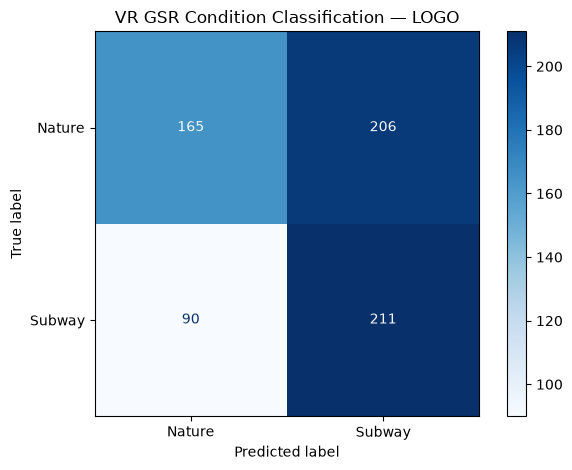

In [30]:

# Final confusion matrix for the best model

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

final_model = models["Logistic Regression"]

final_true = []
final_pred = []

for train_idx, test_idx in logo.split(
    X_selected, y_norm, groups_norm
):
    X_train = X_selected.iloc[train_idx]
    X_test = X_selected.iloc[test_idx]
    y_train = y_norm[train_idx]
    y_test = y_norm[test_idx]

    final_model.fit(X_train, y_train)
    predictions = final_model.predict(X_test)

    final_true.extend(y_test)
    final_pred.extend(predictions)

cm = confusion_matrix(
    final_true,
    final_pred,
    labels=[0, 1]
)

print("FINAL CONFUSION MATRIX")
print("Rows = Actual | Columns = Predicted")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Nature", "Subway"]
).plot(cmap="Blues", values_format="d")

plt.title("VR GSR Condition Classification — LOGO")
plt.tight_layout()
plt.show()



# Final Experimental Results

## Project
Participant-Independent Classification of VR Induction Conditions Using Galvanic Skin Response Signals

## Dataset Summary
- Participants: 17 matched participants
- Conditions: Nature and Subway
- Signal: Galvanic Skin Response (GSR)
- Sampling frequency: 4 Hz
- Window size: 30 seconds (120 samples)
- Overlap: 50%
- Total windows: 672
- Extracted features: 14
- Selected features: 6

## Best Model
Logistic Regression with StandardScaler.

### Preprocessing
Per-recording median-IQR normalization.

### Selected Features
1. Standard deviation
2. Range
3. Interquartile range
4. Slope
5. Mean absolute difference
6. Difference standard deviation

### Validation
Leave-One-Group-Out Cross-Validation (LOGO), using participant identity as the grouping variable.

## Final Performance

| Metric | Score |
|---|---:|
| Accuracy | 55.95% |
| Balanced Accuracy | 57.29% |
| Macro F1 | 55.75% |

## Confusion Matrix

Rows = Actual; Columns = Predicted

| | Predicted Nature | Predicted Subway |
|---|---:|---:|
| Actual Nature | 165 | 206 |
| Actual Subway | 90 | 211 |

## Key Findings
- Per-recording normalization improved performance compared with using original GSR features.
- Selecting six signal-dynamics features improved the Logistic Regression results.
- Participant-balanced sample weighting did not improve balanced accuracy.
- Classification performance varied considerably across participants.
- The model classified Subway windows more successfully than Nature windows.

## Limitations
- Only 17 participants were included in the paired evaluation.
- Performance was modest and varied substantially between participants.
- The dataset labels represent VR induction conditions, not independently verified emotional states.
- Per-recording normalization uses the complete recording and should not be interpreted as a real-time preprocessing method.

## Conclusion
The experiments demonstrate that GSR signal dynamics contain some information for distinguishing Nature and Subway VR induction conditions. However, the observed performance and participant variability indicate that further validation with a larger and more diverse participant population is necessary.
